# RP1 — Mission to Titan: Math & Coding Workbook

## Titan mission design parameters

When designing a mission to Titan, there are a few basic questions that it is absolutely vital to answer:

- **How** can a spacecraft get from Earth's orbit to Saturn's orbit?
- **When** should it leave, and how long will the trip take?
- **How much** propulsion does it need, measured as the total change in speed $\Delta v$?

This notebook helps you answer these questions using the simplest serious model: a **Hohmann transfer**. In a Hohmann transfer, the spacecraft follows the path of half an ellipse around the Sun, from Earth's orbit to Saturn's. As Titan orbits Saturn, arriving near Saturn at the right moment is the first big milestone of our mission.

We are not designing a NASA-grade mission here. Rather, we are using a simplified mathematical model to obtain first mission parameter estimates. The model is straightforward enough that you can derive and check all formulas yourself (using your current knowledge of calculus). It is realistic enough to give you an idea of the orders of magnitude of the relevant parameters and help direct further planning.

## Step by step

Although this part of the project literally is rocket science, it does not have to be overly complicated. This notebook helps you break up your three main questions into the following manageable steps.

| Section | Question | Main mathematical idea |
|---|---|---|
| Setup | Where are Earth and Saturn today? What are our mission constraints? | phase angle |
| A | How fast do Earth and Saturn move? | circles as parametric curves; derivatives |
| B | How are speed and distance related? | orbital energy; the vis-viva equation |
| C | What does the transfer look like, and what does it cost? | the Hohmann ellipse; Kepler's third law |
| D | Does the transfer really work? | Python simulation |
| E | When can we launch? | phase angles |
| F | Does our mission meet its constraints? | |
| G | How do we write this up? | your one-page summary |
| H | What could we be asked? | sample Math questions |

## Simplifying assumptions

We assume that Earth and Saturn move on circular orbits in the same plane; that only the Sun's gravity acts during the transfer; that the engine burns are instantaneous; that there are no gravity assists; and we do not model the actual arrival at Saturn/Titan. Titan is represented by Saturn's orbital distance, plus a small fixed $\Delta v$ to account for the fact that we actually want to approach Titan, not Saturn.

These assumptions make it so that we can cleanly apply our mathematical formulas. Part of your job is to judge which assumptions matter for your conclusion.

## How this notebook works

Every task carries one of three labels.

| Label | What you do | Where it ends up |
|---|---|---|
| **[Do]** | Derive on paper, fill in code, run cells, look at plots. | Key derivations go in your appendix. |
| **[Report R1–R4]** | Four questions, one in each of Sections C–F. | Your one-page summary and its appendix. Section G explains how. |
| **[Q&A]** | A long list of questions that you are strongly encouraged to think about while working through this notebook. | These questions are similar to ones that may be asked during your Q&A session. |

The Q&A questions are marked by expected difficulty:
- ★ — everyone in the group should be able to answer these;
- ★★ — these need a good understanding of the section;
- ★★★ — stretch questions that go beyond the material this notebook introduces, connecting the model to the real mission or to other disciplines. You are not expected to have a full answer for these questions at the ready. They are more open-ended and direct you towards further exploration.

Any group member may be asked any question, so make sure that everyone works through every section.

## The Python you need

To complete this notebook, you will not need any Python beyond what we have covered in the course.

Some cells contain specialized (and scary-looking) code; they are marked **Run only**. This code will help you generate pretty plots. Run these cells, but you do not need to read or edit them.

To avoid errors, always run the notebook from top to bottom. If you restart the kernel or change your group code, use *Run All*.

## What to submit

- **The math part of your project report:** a one-page summary plus up to two pages of appendix (figures, tables, derivations). Section G explains what goes where.
- **This notebook, completed**, in a **shared GitHub repository used by all group members**. All group members must have access to the repository, and so must the instructors and TAs.

As a reminder, the GitHub usernames of your math instructors and TAs are
- stoutm1 (stoutm1@mcmaster.ca)
- KathrineMondshain
- RishabhDBhatia
- srutipraba

# Setup — your group's scenario

**[Do]** Run the next cell. Depending on your editor, it may appear collapsed because it only contains helper code (the scenario generator, plots and animations). You do not need to open it.

Your group code is `G` followed by your two-digit group number from the group assignment table (for example, group 7 uses `G07`). It determines three things.

1. **Where Saturn is today, relative to Earth.** We measure this with the **phase angle**
$$
\phi=\theta_{\text{Saturn}}-\theta_{\text{Earth}}\pmod{2\pi},
$$
where $\theta$ is the angle of a planet's position around the Sun, measured counterclockwise. We choose our axes so that Earth starts at $\theta_{\text{Earth}}=0$ today. This means that Saturn starts at $\theta_{\text{Saturn}}=\phi_{\text{now}}$.
2. **Your arrival deadline:** the spacecraft must reach Saturn's orbit at most this many years from today. (Real deadlines come from the lifetime of the power source, from funding, or from Titan's seasons.)
3. **Your $\Delta v$ budget:** the largest total change in speed that your spacecraft's engines can deliver.

Different groups therefore get different launch dates and possibly different conclusions, while using exactly the same mathematics.

**[Do]** Set your group code in the next cell and run it.

In [24]:
#@title Run only — helper code for the scenario, plots and animations (no need to open this cell)
# Run this cell once at the start. You do not need to read or edit it.
from hashlib import sha256

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Arc
from matplotlib.animation import FuncAnimation
from IPython.display import Markdown, display

rcParams["animation.html"] = "jshtml"
rcParams["animation.embed_limit"] = 30  # MB

EARTH_COLOR, SATURN_COLOR, CRAFT_COLOR, SIM_COLOR = "tab:blue", "tab:orange", "tab:green", "tab:red"


# ----------------------------------------------------------------------------- group scenario

def code_to_phase(code):
    """Deterministic phase angle in [0, 2*pi) from a group code such as 'G07'."""
    h = sha256(code.encode()).hexdigest()
    return float(2*np.pi*int(h[:8], 16)/16**8)


def group_scenario(code):
    """Return (phi_now, deadline_years, dv_budget_kms) for a group code."""
    h = sha256(code.encode()).hexdigest()
    deadlines = [6.5, 6.7, 7.0, 7.5]      # arrival deadline, years from today
    budgets = [14.5, 15.5, 16.5, 18.0]    # total delta-v the spacecraft can deliver, km/s
    deadline = deadlines[int(h[8:16], 16) % len(deadlines)]
    budget = budgets[int(h[16:24], 16) % len(budgets)]
    return code_to_phase(code), deadline, budget


def check_group_code(code):
    """Return the group code in the standard form 'G07' (also accepts 'G7', 'g07' or '7')."""
    digits = "".join(ch for ch in str(code) if ch.isdigit())
    if not digits:
        print(f"Warning: {code!r} is not a valid group code. Use G followed by your two-digit group number, e.g. 'G07'.")
        return code
    standard = f"G{int(digits):02d}"
    if standard != code:
        print(f"Note: using the group code {standard!r} (you entered {code!r}).")
    return standard


# ----------------------------------------------------------------------------- utilities

def _get(name):
    """Value of a notebook variable, or None if it does not exist yet."""
    return globals().get(name)


def _hohmann_or_none():
    """Your hohmann_outer() for Earth to Saturn, or None if it is not complete yet."""
    if _get("hohmann_outer") is None:
        return None
    out = hohmann_outer(r_earth, r_saturn, mu)
    if out is None or any(value is None for value in out):
        return None
    return out


def _mean_motions():
    return np.sqrt(mu/r_earth**3), np.sqrt(mu/r_saturn**3)


def orbit_circle_xy(r, num=720):
    th = np.linspace(0, 2*np.pi, num)
    return r*np.cos(th), r*np.sin(th)


def orbit_ellipse_xy(a, e, nu_start=0.0, nu_end=2*np.pi, num=900):
    """Ellipse with the Sun at a focus and perihelion on the +x axis (polar form r(nu))."""
    nu = np.linspace(nu_start, nu_end, num)
    r = a*(1 - e**2)/(1 + e*np.cos(nu))
    return r*np.cos(nu), r*np.sin(nu)


def rotate_xy(x, y, angle):
    c, s = np.cos(angle), np.sin(angle)
    return c*x - s*y, s*x + c*y


def _draw_orbits(ax, lim=None):
    for r, name, color in [(r_earth, "Earth orbit", EARTH_COLOR), (r_saturn, "Saturn orbit", SATURN_COLOR)]:
        x, y = orbit_circle_xy(r)
        ax.plot(x/AU, y/AU, color=color, lw=1, alpha=0.6, label=name)
    ax.scatter([0], [0], marker="*", s=180, color="gold", edgecolor="k", zorder=4, label="Sun")
    lim = lim if lim is not None else 1.12*r_saturn/AU
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("x (AU)")
    ax.set_ylabel("y (AU)")
    ax.grid(alpha=0.2)


def _draw_angle(ax, th_from, th_to, label, radius=3.0):
    """Dashed rays from the Sun at two angles, with an arc and a label for the angle between them."""
    sweep = (th_to - th_from) % (2*np.pi)
    L = 1.08*r_saturn/AU
    for th in (th_from, th_to):
        ax.plot([0, L*np.cos(th)], [0, L*np.sin(th)], "k--", lw=0.8)
    start = np.degrees(th_from) % 360
    ax.add_patch(Arc((0, 0), 2*radius, 2*radius, theta1=start, theta2=start + np.degrees(sweep), lw=1.5))
    mid = th_from + sweep/2
    ax.text(1.35*radius*np.cos(mid), 1.35*radius*np.sin(mid), label, fontsize=13, ha="center", va="center")


def _legend_outside(ax):
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)


def _finish(fig, save_as):
    fig.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=200, bbox_inches="tight")
        plt.close(fig)
        print(f"Saved {save_as}")
    else:
        plt.show()


# ----------------------------------------------------------------------------- Setup and Section C plots

def plot_phase_angle(phi_now, save_as=None):
    """Both orbits, today's positions, and the current phase angle phi_now."""
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    _draw_orbits(ax)
    ax.scatter([r_earth/AU], [0], s=50, color=EARTH_COLOR, zorder=5, label="Earth today")
    ax.scatter([r_saturn*np.cos(phi_now)/AU], [r_saturn*np.sin(phi_now)/AU], s=80, color=SATURN_COLOR,
               zorder=5, label="Saturn today")
    _draw_angle(ax, 0.0, phi_now, r"$\phi_{now}$")
    ax.set_title(f"{GROUP_CODE}: phase angle today = {np.degrees(phi_now):.1f}° = {phi_now:.3f} rad")
    _legend_outside(ax)
    _finish(fig, save_as)


def plot_transfer_ellipse(save_as=None):
    """The Hohmann transfer ellipse from Section C, with perihelion on the +x axis."""
    out = _hohmann_or_none()
    if out is None:
        print("Complete hohmann_outer() in Section C first.")
        return
    a_t, e_t, t_t, v_p, v_a, dv1, dv2 = out
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    _draw_orbits(ax)
    x, y = orbit_ellipse_xy(a_t, e_t)
    ax.plot(x/AU, y/AU, ":", color=CRAFT_COLOR, lw=1, label="full transfer ellipse")
    x, y = orbit_ellipse_xy(a_t, e_t, 0, np.pi)
    ax.plot(x/AU, y/AU, color=CRAFT_COLOR, lw=2.2, label="Hohmann transfer (half ellipse)")
    ax.scatter([r_earth/AU], [0], marker="s", s=50, color=EARTH_COLOR, zorder=5,
               label=f"departure burn: Δv1 = {dv1/1000:.2f} km/s")
    ax.scatter([-r_saturn/AU], [0], marker="X", s=100, color=SATURN_COLOR, zorder=5,
               label=f"arrival burn: Δv2 = {dv2/1000:.2f} km/s")
    ax.set_title(f"Hohmann transfer: a_t = {a_t/AU:.2f} AU, e_t = {e_t:.3f}, t_t = {t_t/year:.2f} years")
    _legend_outside(ax)
    _finish(fig, save_as)


# ----------------------------------------------------------------------------- Section D: recording and plotting a simulated flight

_flight = {"t": [], "x": [], "y": [], "vx": [], "vy": []}


def start_recording():
    """Forget the previous flight. Called at the start of simulate_transfer()."""
    for values in _flight.values():
        values.clear()


def record(t, x, y, vx, vy):
    """Remember one state of the simulated flight, for plotting."""
    for key, value in zip(("t", "x", "y", "vx", "vy"), (t, x, y, vx, vy)):
        _flight[key].append(float(value))


def plot_flight(save_as=None):
    """The most recent simulated flight: its path, and its speed over time."""
    if len(_flight["t"]) < 2:
        print("Run simulate_transfer() first.")
        return
    t, x, y, vx, vy = (np.array(_flight[key]) for key in ("t", "x", "y", "vx", "vy"))
    speed = np.sqrt(vx**2 + vy**2)
    dt = t[1] - t[0]
    out = _hohmann_or_none()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.8))
    _draw_orbits(ax1, lim=max(1.12*r_saturn, 1.05*np.max(np.abs(x)), 1.05*np.max(np.abs(y)))/AU)
    if out is not None:
        xe, ye = orbit_ellipse_xy(out[0], out[1], 0, np.pi)
        ax1.plot(xe/AU, ye/AU, "--", color=CRAFT_COLOR, lw=1.5, label="Hohmann ellipse (Section C)")
    ax1.plot(x/AU, y/AU, color=SIM_COLOR, lw=1.5, label="simulated flight")
    marks = np.searchsorted(t, np.arange(0, t[-1], 0.5*year))
    ax1.scatter(x[marks]/AU, y[marks]/AU, s=20, color=SIM_COLOR, zorder=5, label="position every 6 months")
    ax1.scatter([x[-1]/AU], [y[-1]/AU], marker="X", s=80, color=SIM_COLOR, zorder=6, label="end of simulation")
    ax1.set_title(f"Simulated flight (dt = {dt/day:g} day{'' if abs(dt - day) < 1 else 's'})")
    ax1.legend(loc="lower center", fontsize=8)

    ax2.plot(t/year, speed/1000, color=SIM_COLOR, label="simulated speed")
    if out is not None:
        ax2.axhline(out[3]/1000, ls="--", color=CRAFT_COLOR, lw=1, label=f"v_p = {out[3]/1000:.2f} km/s (vis-viva)")
        ax2.axhline(out[4]/1000, ls=":", color=CRAFT_COLOR, lw=1, label=f"v_a = {out[4]/1000:.2f} km/s (vis-viva)")
    ax2.set_xlabel("time since launch (years)")
    ax2.set_ylabel("speed (km/s)")
    ax2.set_title("Speed during the flight")
    ax2.grid(alpha=0.3)
    ax2.legend(fontsize=8)
    _finish(fig, save_as)


# ----------------------------------------------------------------------------- Section E: launch geometry

def plot_launch_geometry(t_wait, save_as=None):
    """Positions today, at launch and at arrival, with the transfer rotated to the launch direction."""
    out = _hohmann_or_none()
    if out is None or t_wait is None:
        print("Complete hohmann_outer() (Section C) and t_wait (Section E) first.")
        return
    a_t, e_t, t_t = out[0], out[1], out[2]
    n1, n2 = _mean_motions()
    th_launch = n1*t_wait                  # Earth's angle at launch = direction of perihelion
    th_saturn_launch = phi_now + n2*t_wait
    th_arrival = th_launch + np.pi         # direction of aphelion

    def pos(r, th):
        return [r*np.cos(th)/AU], [r*np.sin(th)/AU]

    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    _draw_orbits(ax)
    x, y = rotate_xy(*orbit_ellipse_xy(a_t, e_t, 0, np.pi), th_launch)
    ax.plot(x/AU, y/AU, color=CRAFT_COLOR, lw=2.2, label="transfer (half ellipse)")
    ax.scatter(*pos(r_earth, 0.0), s=45, facecolor="none", edgecolor=EARTH_COLOR, zorder=5, label="Earth today")
    ax.scatter(*pos(r_saturn, phi_now), s=80, facecolor="none", edgecolor=SATURN_COLOR, zorder=5, label="Saturn today")
    ax.scatter(*pos(r_earth, th_launch), s=50, marker="s", color=EARTH_COLOR, zorder=5, label="Earth at launch")
    ax.scatter(*pos(r_saturn, th_saturn_launch), s=80, marker="s", color=SATURN_COLOR, zorder=5,
               label="Saturn at launch")
    ax.scatter(*pos(r_saturn, th_arrival), s=120, marker="X", color=CRAFT_COLOR, zorder=6,
               label="arrival: spacecraft meets Saturn")
    _draw_angle(ax, th_launch, th_saturn_launch, r"$\phi^*$")
    ax.set_title(f"{GROUP_CODE}: launch after {t_wait/day:.0f} days, arrival {(t_wait + t_t)/year:.2f} years from today")
    _legend_outside(ax)
    _finish(fig, save_as)


# ----------------------------------------------------------------------------- Run-only extra: Kepler-timed animation

def solve_kepler_elliptic(M, e, tol=1e-12, max_iter=30):
    """Solve Kepler's equation M = E - e sin(E) for the eccentric anomaly E (Newton's method)."""
    E = np.array(M, dtype=float)
    for _ in range(max_iter):
        step = (E - e*np.sin(E) - M)/(1 - e*np.cos(E))
        E = E - step
        if np.max(np.abs(step)) < tol:
            break
    return E


def true_anomaly_on_transfer(tau, a, e, motion_model="exact"):
    """Angle travelled from perihelion after time tau on the transfer (0 <= tau <= t_t)."""
    t_transfer = np.pi*np.sqrt(a**3/mu)
    s = np.clip(np.asarray(tau, dtype=float)/t_transfer, 0.0, 1.0)
    if motion_model == "simple":
        return s*np.pi                       # constant angular rate: right path, wrong timing
    if motion_model != "exact":
        raise ValueError('motion_model must be "exact" or "simple"')
    E = solve_kepler_elliptic(s*np.pi, e)    # the mean anomaly runs from 0 to pi
    return 2*np.arctan2(np.sqrt(1 + e)*np.sin(E/2), np.sqrt(1 - e)*np.cos(E/2))


def spacecraft_position_on_transfer(tau, theta0, a, e, motion_model="exact"):
    nu = true_anomaly_on_transfer(tau, a, e, motion_model)
    r = a*(1 - e**2)/(1 + e*np.cos(nu))
    return r*np.cos(theta0 + nu), r*np.sin(theta0 + nu)


def transfer_speed_exact(tau, a, e):
    """Physical speed after time tau on the transfer (vis-viva at the Kepler-timed position)."""
    nu = true_anomaly_on_transfer(tau, a, e, "exact")
    r = a*(1 - e**2)/(1 + e*np.cos(nu))
    return np.sqrt(mu*(2/r - 1/a))


def animate_delayed_launch(t_wait, motion_model="exact", frames=120, interval=70):
    """Animate the wait for the launch window, the launch, and the coast to Saturn's orbit."""
    out = _hohmann_or_none()
    if out is None or t_wait is None:
        print("Complete hohmann_outer() (Section C) and t_wait (Section E) first.")
        return None
    a_t, e_t, t_t = out[0], out[1], out[2]
    n1, n2 = _mean_motions()
    theta0 = n1*t_wait
    times = np.linspace(0.0, t_wait + t_t, int(frames))

    fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=72)   # low resolution keeps the notebook file small
    _draw_orbits(ax)
    x, y = rotate_xy(*orbit_ellipse_xy(a_t, e_t, 0, np.pi), theta0)
    ax.plot(x/AU, y/AU, color=CRAFT_COLOR, lw=1, alpha=0.7, label="transfer path")
    p_earth, = ax.plot([], [], "o", color=EARTH_COLOR, label="Earth")
    p_saturn, = ax.plot([], [], "o", ms=9, color=SATURN_COLOR, label="Saturn")
    p_craft, = ax.plot([], [], "o", ms=5, color="k", label="spacecraft")
    info = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top", ha="left", fontsize=9, family="monospace")
    ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"{GROUP_CODE}: whole mission, {motion_model} timing")

    def update(i):
        t = times[i]
        p_earth.set_data([r_earth*np.cos(n1*t)/AU], [r_earth*np.sin(n1*t)/AU])
        p_saturn.set_data([r_saturn*np.cos(phi_now + n2*t)/AU], [r_saturn*np.sin(phi_now + n2*t)/AU])
        if t < t_wait:
            xc, yc = r_earth*np.cos(n1*t), r_earth*np.sin(n1*t)
            status = "waiting for the launch window"
        else:
            tau = t - t_wait
            xc, yc = spacecraft_position_on_transfer(tau, theta0, a_t, e_t, motion_model)
            if motion_model == "exact":
                status = f"transfer: v = {transfer_speed_exact(tau, a_t, e_t)/1000:5.2f} km/s"
            else:
                status = "transfer (simple timing: not physical)"
        p_craft.set_data([xc/AU], [yc/AU])
        info.set_text(f"t = {t/year:5.2f} years\n{status}")
        return p_earth, p_saturn, p_craft, info

    anim = FuncAnimation(fig, update, frames=len(times), interval=interval, blit=False)
    plt.close(fig)
    return anim


def plot_equal_time_markers(samples=13):
    """Positions after equal time steps along the transfer: exact (Kepler) timing vs simple timing."""
    out = _hohmann_or_none()
    if out is None:
        print("Complete hohmann_outer() in Section C first.")
        return
    a_t, e_t, t_t = out[0], out[1], out[2]
    tau = np.linspace(0, t_t, samples)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
    for ax, model in zip(axes, ("exact", "simple")):
        _draw_orbits(ax)
        xe, ye = orbit_ellipse_xy(a_t, e_t, 0, np.pi)
        ax.plot(xe/AU, ye/AU, color=CRAFT_COLOR, lw=1.5, label="transfer path")
        x, y = spacecraft_position_on_transfer(tau, 0.0, a_t, e_t, model)
        ax.scatter(x/AU, y/AU, s=30, color="k", zorder=5, label=f"positions at {samples} equal time steps")
        ax.set_title(f"{model} timing")
        ax.legend(loc="lower center", fontsize=8)
    _finish(fig, None)


def plot_transfer_speed_profile(samples=300):
    """Physical speed along the transfer from Kepler's equation (compare with your Section D plot)."""
    out = _hohmann_or_none()
    if out is None:
        print("Complete hohmann_outer() in Section C first.")
        return
    a_t, e_t, t_t = out[0], out[1], out[2]
    tau = np.linspace(0, t_t, samples)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(tau/year, transfer_speed_exact(tau, a_t, e_t)/1000, color=CRAFT_COLOR)
    ax.set_xlabel("time since launch (years)")
    ax.set_ylabel("speed (km/s)")
    ax.set_title("Speed along the transfer (Kepler's equation)")
    ax.grid(alpha=0.3)
    _finish(fig, None)


# ----------------------------------------------------------------------------- Section G: results table and figure export

def print_results_table():
    """Your key results as a table (Table A1 in your appendix). A dash means: not computed yet."""
    def show(name, scale=1.0, fmt="{:.2f}", unit=""):
        value = _get(name)
        if value is None:
            return "—"
        return fmt.format(value/scale) + (f" {unit}" if unit else "")

    def show_angle(name):
        value = _get(name)
        if value is None:
            return "—"
        return f"{value:.4f} rad = {np.degrees(value):.2f}°"

    rows = [
        ("Group code", "", GROUP_CODE),
        ("Earth's orbital speed", r"$v_{\text{circ}}(r_1)$", show("v_earth", 1000, unit="km/s")),
        ("Saturn's orbital speed", r"$v_{\text{circ}}(r_2)$", show("v_saturn", 1000, unit="km/s")),
        ("Semi-major axis of the transfer ellipse", "$a_t$", show("a_t", AU, "{:.3f}", "AU")),
        ("Eccentricity of the transfer ellipse", "$e_t$", show("e_t", 1, "{:.3f}")),
        ("Flight time (Hohmann formula)", "$t_t$", show("t_t", year, "{:.3f}", "years")),
        ("Speed on the ellipse at departure", "$v_p$", show("v_p", 1000, unit="km/s")),
        ("Speed on the ellipse at arrival", "$v_a$", show("v_a", 1000, unit="km/s")),
        ("Departure burn", r"$\Delta v_1$", show("dv1", 1000, unit="km/s")),
        ("Arrival burn", r"$\Delta v_2$", show("dv2", 1000, unit="km/s")),
        ("Flight time (simulation, dt = 1 day)", "", show("t_sim", year, "{:.3f}", "years")),
        ("Aphelion distance (simulation, dt = 1 day)", "", show("r_sim", AU, "{:.3f}", "AU")),
        ("Phase angle today", r"$\phi_{\text{now}}$", show_angle("phi_now")),
        ("Required phase angle at launch", r"$\phi^*$", show_angle("phi_req")),
        ("Waiting time until launch", r"$t_{\text{wait}}$", show("t_wait", day, "{:.0f}", "days")),
        ("Arrival, years from today", "", show("total_years", 1, "{:.2f}", "years")),
        ("Arrival deadline", "", f"{deadline_years:.2f} years"),
        (r"Mission $\Delta v$ (incl. Titan-approach allowance)", "", show("mission_dv_kms", 1, unit="km/s")),
        (r"$\Delta v$ budget", "", f"{dv_budget_kms:.2f} km/s"),
    ]
    lines = ["| Quantity | Symbol | Value |", "|---|---|---|"]
    lines += [f"| {quantity} | {symbol} | {value} |" for quantity, symbol, value in rows]
    display(Markdown("\n".join(lines)))


def export_report_figures():
    """Save the main figures as PNG files in the same folder as this notebook."""
    prefix = f"{GROUP_CODE}_"
    plot_phase_angle(phi_now, save_as=prefix + "phase_angle_today.png")
    plot_transfer_ellipse(save_as=prefix + "hohmann_transfer.png")
    if _get("simulate_transfer") is not None and _get("v_p") is not None:
        simulate_transfer(v_p, 1*day)   # redo the main run, in case an experiment was the last flight
        plot_flight(save_as=prefix + "simulated_flight.png")
    plot_launch_geometry(_get("t_wait"), save_as=prefix + "launch_geometry.png")

In [25]:
import numpy as np

# === Your group code ===
GROUP_CODE = "G02"   # TODO: change to G + your two-digit group number, e.g. "G07" for group 7

# Physical constants (SI units)
G = 6.67430e-11        # gravitational constant, m^3/(kg s^2)
M_sun = 1.98847e30     # mass of the Sun, kg
mu = G*M_sun           # gravitational parameter of the Sun, m^3/s^2
AU = 1.495978707e11    # astronomical unit, m
r_earth = 1.0*AU       # radius of Earth's orbit (assumed circular), m
r_saturn = 9.537*AU    # radius of Saturn's orbit (assumed circular), m

# Units
day = 24*3600          # s
year = 365.25*day      # s


def seconds_to_days(t):
    return t/day


def seconds_to_years(t):
    return t/year


def mps_to_kms(v):
    return v/1000


# Your group's scenario, computed from the group code
GROUP_CODE = check_group_code(GROUP_CODE)
phi_now, deadline_years, dv_budget_kms = group_scenario(GROUP_CODE)
arrival_allowance_kms = 0.3   # extra delta-v for the final approach to Titan (the same for all groups)

print(f"Group {GROUP_CODE}")
print(f"  Phase angle today   phi_now = {phi_now:.4f} rad = {np.degrees(phi_now):.2f} degrees")
print(f"  Arrival deadline            = {deadline_years:.2f} years from today")
print(f"  Delta-v budget              = {dv_budget_kms:.2f} km/s")

Group G02
  Phase angle today   phi_now = 1.8137 rad = 103.92 degrees
  Arrival deadline            = 6.50 years from today
  Delta-v budget              = 15.50 km/s


## Where are Earth and Saturn today?

**[Do]** Run the next cell (**Run only**). It draws both orbits and your group's phase angle $\phi_{\text{now}}$. Check that the angle in the plot matches the printed value.

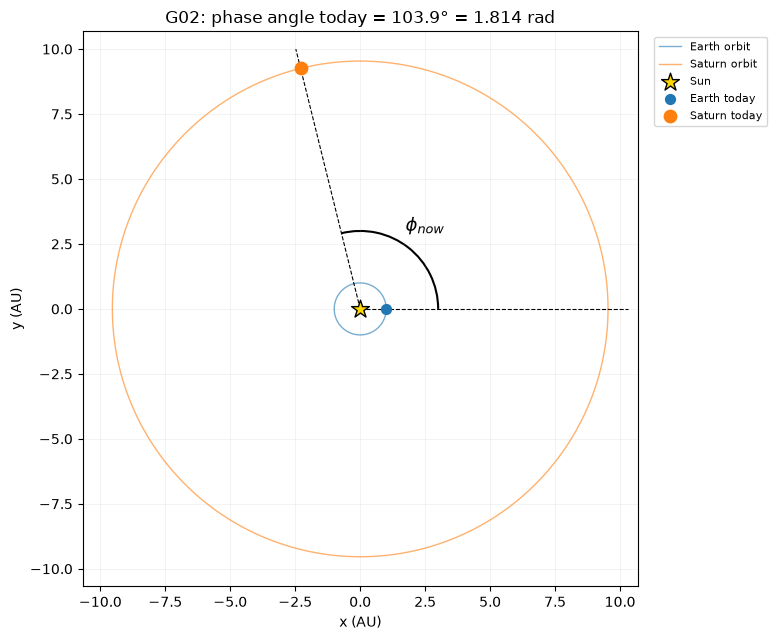

In [26]:
# Run only
plot_phase_angle(phi_now)

## Symbols used in this notebook

- $\mu=GM_\odot$: gravitational parameter of the Sun.
- $r_1=r_{\text{Earth}}$ and $r_2=r_{\text{Saturn}}$: radii of Earth's and Saturn's orbits (assumed circular).
- $n$: angular speed of a circular orbit (also called the *mean motion*), in rad/s. The period is $T=2\pi/n$. We write $n_1$ for Earth and $n_2$ for Saturn.
- $v_{\text{circ}}(r)$: speed on a circular orbit of radius $r$.
- $\varepsilon$: specific orbital energy (energy per kilogram of spacecraft).
- $a$ and $e$: semi-major axis and eccentricity of an ellipse. Then $r_p=a(1-e)$ and $r_a=a(1+e)$ are the closest (perihelion) and farthest (aphelion) distances from the Sun.
- $a_t$, $e_t$, $t_t$: semi-major axis, eccentricity and flight time of the transfer ellipse.
- $v_p$, $v_a$: the spacecraft's speed at perihelion (departure) and at aphelion (arrival).
- $\Delta v_1$, $\Delta v_2$: the speed changes of the departure burn and the arrival burn.
- $\phi_{\text{now}}$ and $\phi^*$: the phase angle today, and the phase angle required at launch. $t_{\text{wait}}$ is the waiting time until launch.
- $\Delta t$ (`dt` in the code): the time step of a simulation.

### Using symbols in your report

Ensure that you define any symbols you might use in your report.

# Section A — Circular orbits as parametric curves

We start with the simplest model of a planet's motion: a circle of radius $r$ around the Sun, travelled at a constant angular speed $n$ (in rad/s). As a **parametric curve**, with time $t$ as the parameter, the position is
$$
x(t)=r\cos(nt),\qquad y(t)=r\sin(nt).
$$
In **polar coordinates** the same motion is simply $r=\text{constant}$, $\theta(t)=nt$.

In our simplified picture, planets are kept in these orbits by gravity: the Sun pulls any planet towards it with an acceleration of magnitude $\mu/r^2$.

**[Do] A1.** Find the velocity vector $(x'(t),y'(t))$ and the acceleration vector $(x''(t),y''(t))$ by differentiating with respect to $t$. The speed and acceleration are given by the sizes of these vectors: $v = \sqrt{(x'(t))^2 + (y'(t))^2}$, and $a = \sqrt{(x''(t))^2 + (y''(t))^2}$. Show that $v = rn$ and $a = rn^2$.

**[Do] A2.** In a circular orbit, gravity is the only acceleration, so $a = \mu/r^2$. Use this to express $n$ and the circular speed $v_{\text{circ}}=rn$ in terms of $\mu$ and $r$. Use this to determine the period of the orbit $T=2\pi/n$.

<details>
<summary><b>Check your answers to A2</b> (open this only after you have tried)</summary>

$$
n=\sqrt{\frac{\mu}{r^3}},\qquad v_{\text{circ}}(r)=\sqrt{\frac{\mu}{r}},\qquad T=2\pi\sqrt{\frac{r^3}{\mu}}.
$$

The last formula is Kepler's third law for circular orbits.

</details>

**[Do] A3.** Complete `v_circ` and `mean_motion` below, then run the cell and read the check. The mathematical function $\sqrt{x}$ can be computed using the Python function `np.sqrt(x)`.

In [27]:
def v_circ(r, mu):
    """Speed on a circular orbit of radius r around the Sun."""

    return np.sqrt(mu/r)


def mean_motion(r, mu):
    """Angular speed n (in rad/s) on a circular orbit of radius r."""
    return np.sqrt(mu/(r**3))


v_earth = v_circ(r_earth, mu)
v_saturn = v_circ(r_saturn, mu)
n_earth = mean_motion(r_earth, mu)
n_saturn = mean_motion(r_saturn, mu)

if v_earth is None or v_saturn is None or n_earth is None or n_saturn is None:
    print("Complete v_circ and mean_motion, then run this cell again.")
else:
    print(f"Earth:  speed {mps_to_kms(v_earth):.2f} km/s, period {seconds_to_years(2*np.pi/n_earth):.3f} years")
    print(f"Saturn: speed {mps_to_kms(v_saturn):.2f} km/s, period {seconds_to_years(2*np.pi/n_saturn):.2f} years")
    if abs(mps_to_kms(v_earth) - 29.78) < 0.1 and abs(seconds_to_years(2*np.pi/n_earth) - 1) < 0.01:
        print("Check: OK")
    else:
        print("Check: Earth should move at about 29.8 km/s, with a period of about 1 year. Look at your formulas again.")

Earth:  speed 29.79 km/s, period 1.000 years
Saturn: speed 9.64 km/s, period 29.45 years
Check: OK


### [Q&A] Section A — Circular orbits

*These questions give you an idea of what you may be asked during the Q&A session. They are not a definitive question bank. Rather, thinking about these as you go through this notebook will help you deepen your understanding and prepare for the Q&A.*

- **Q-A1** ★ The circular orbit model is described using a parametric curve. Which parameter does it depend on and what is its physical meaning? What do $r$ and $n$ mean physically? What are the units of $n$?
- **Q-A2** ★★ Why are Saturn years longer than Earth years? Support your answer with a formula.
- **Q-A3** ★★★ Real planetary orbits are slightly elliptical (Earth: $e\approx0.017$; Saturn: $e\approx0.052$). Roughly how much does Saturn's distance from the Sun vary, and how could this affect the mission?

# Section B — Orbital energy and the vis-viva equation

The transfer orbit will be an ellipse, not a circle, so we need a relation between speed and distance that also works on ellipses.

The **specific orbital energy** (the energy per kilogram of spacecraft) is kinetic energy plus gravitational potential energy:
$$
\varepsilon=\frac{v^2}{2}-\frac{\mu}{r}.
$$
Because gravity is the only force acting, $\varepsilon$ stays constant along the whole orbit. For an ellipse with semi-major axis $a$, one can show (see Knight, Chapter 13) that
$$
\varepsilon=-\frac{\mu}{2a}.
$$

**[Do] B1.** For a circular orbit, use $v_{\text{circ}}=\sqrt{\mu/r}$ to show that $\varepsilon=-\mu/(2r)$. Why is this consistent with $\varepsilon=-\mu/(2a)$?

**[Do] B2.** Set the two expressions for $\varepsilon$ equal to each other and solve for $v$. The result is the **vis-viva equation** $v(r,a)$: the speed at distance $r$ on any orbit with semi-major axis $a$.

<details>
<summary><b>Check your answer to B2</b> (open this only after you have tried)</summary>

$$
v(r,a)=\sqrt{\mu\left(\frac{2}{r}-\frac{1}{a}\right)}.
$$

</details>

**[Do] B3.** Complete `energy_specific` and `vis_viva_speed` below, then run the cell and read the check.

In [28]:
def energy_specific(a, mu):
    """Specific orbital energy (J/kg) of an orbit with semi-major axis a."""
    return ((-1*mu)/(2*a))


def vis_viva_speed(r, a, mu):
    """Speed at distance r on an orbit with semi-major axis a."""
    return np.sqrt(mu*((2/r)-(1/a)))


eps_earth = energy_specific(r_earth, mu)
eps_saturn = energy_specific(r_saturn, mu)
v_test = vis_viva_speed(r_earth, r_earth, mu)   # a circle is an ellipse with a = r

if eps_earth is None or eps_saturn is None or v_test is None:
    print("Complete energy_specific and vis_viva_speed, then run this cell again.")
else:
    print(f"Energy of Earth's orbit:  {eps_earth:.3e} J/kg")
    print(f"Energy of Saturn's orbit: {eps_saturn:.3e} J/kg")
    print(f"Vis-viva speed on Earth's circular orbit: {mps_to_kms(v_test):.2f} km/s")
    if abs(eps_earth/(-4.436e8) - 1) < 0.01 and abs(mps_to_kms(v_test) - 29.78) < 0.1:
        print("Check: OK")
    else:
        print("Check: expected about -4.44e8 J/kg for Earth, and vis-viva should give Earth's circular speed (29.8 km/s).")

Energy of Earth's orbit:  -4.436e+08 J/kg
Energy of Saturn's orbit: -4.651e+07 J/kg
Vis-viva speed on Earth's circular orbit: 29.79 km/s
Check: OK


### [Q&A] Section B — Orbital energy and vis-viva

*These questions give you an idea of what you may be asked during the Q&A session. They are not a definitive question bank. Rather, thinking about these as you go through this notebook will help you deepen your understanding and prepare for the Q&A.*

- **Q-B1** ★ What does the sign of $\varepsilon$ tell you? Which planet is more tightly bound to the Sun, Earth or Saturn? What does 'more tightly bound' mean here?
- **Q-B2** ★ On an elliptical orbit, where is the spacecraft fastest, and where is it slowest? How does this relate to conservation of energy?
- **Q-B3** ★★ By setting $\varepsilon=0$, you can find the speed a spacecraft needs to escape the Sun's gravity, starting at a radius $r$ from the Sun. Explain why this works. Do this computation for a spacecraft starting from Earth's orbit, by setting $r = r_1$.
- **Q-B4** ★★ The vis-viva equation contains $a$ but not $e$. What does this mean physically?
- **Q-B5** ★★★ The energy difference between Saturn's orbit and Earth's orbit is about $4\times10^{8}$ J per kilogram. Why can't we simply convert this energy difference to obtain our mission's $\Delta v$?

# Section C — The Hohmann transfer

A **Hohmann transfer** moves a spacecraft between two circular orbits in the same plane, using two short engine burns:

1. **Departure burn** $\Delta v_1$ at Earth's orbit: speed up from Earth's circular speed onto the transfer ellipse.
2. **Coast** along half of the ellipse, with the engine off.
3. **Arrival burn** $\Delta v_2$ at Saturn's orbit: speed up again to match Saturn's circular speed.

The transfer ellipse is **tangent** to Earth's orbit at its perihelion and to Saturn's orbit at its aphelion. At these two points the ellipse and the circle have the same tangent line, so the velocity on the ellipse is parallel to the planet's velocity. A burn along the direction of motion therefore changes only the speed, not the direction. One can show that this makes it the most efficient way to switch between the two orbits (if you only allow two burns).

**[Do] C1 — Geometry.** Tangency means that the perihelion distance equals $r_1$ and the aphelion distance equals $r_2$:
$$
a_t(1-e_t)=r_1,\qquad a_t(1+e_t)=r_2.
$$
Solve these two equations for $a_t$ and $e_t$.

**[Do] C2 — Flight time.** A full trip around an ellipse takes $T=2\pi\sqrt{a^3/\mu}$ (Kepler's third law: the formula from A2, with $r$ replaced by $a$). How long does the transfer take?

**[Do] C3 — Speeds and burns.** Use the vis-viva equation to write the speeds $v_p$ (at distance $r_1$) and $v_a$ (at distance $r_2$) on the transfer ellipse. Then write $\Delta v_1$ and $\Delta v_2$ as differences of speeds you already know. Is each burn a speed-up or a slow-down?

<details>
<summary><b>Check your answers to C1–C3</b> (open this only after you have tried)</summary>

$$
a_t=\frac{r_1+r_2}{2},\qquad e_t=\frac{r_2-r_1}{r_2+r_1},\qquad t_t=\pi\sqrt{\frac{a_t^3}{\mu}},
$$

$$
v_p=v(r_1,a_t),\qquad v_a=v(r_2,a_t),\qquad \Delta v_1=v_p-v_{\text{circ}}(r_1),\qquad \Delta v_2=v_{\text{circ}}(r_2)-v_a.
$$

</details>

**[Do] C4.** Complete `hohmann_outer` below. Use your functions `v_circ` and `vis_viva_speed` from Sections A and B. Then run the cell, read the check, and run the plot cell after it.

In [29]:
def hohmann_outer(r1, r2, mu):
    """Hohmann transfer from an inner circular orbit (radius r1) to an outer one (radius r2).
    Returns a_t, e_t, t_t, v_p, v_a, dv1, dv2 (in SI units)."""
    import numpy
    a_t = (r1+r2)/2   # TODO: semi-major axis of the transfer ellipse)
    e_t = (r2-r1)/(r2+r1)   # TODO: eccentricity of the transfer ellipse
    t_t = numpy.pi*(np.sqrt((a_t**3)/mu))# TODO: flight time (half of the period)
    v_p = vis_viva_speed(r1,a_t,mu)# TODO: speed on the ellipse at r1 (use vis_viva_speed)
    v_a = vis_viva_speed(r2,a_t,mu)# TODO: speed on the ellipse at r2 (use vis_viva_speed)
    dv1 = v_p - v_circ(r1,mu)# TODO: departure burn (use v_circ)
    dv2 = v_circ(r2,mu) - v_a   # TODO: arrival burn (use v_circ)
    return a_t, e_t, t_t, v_p, v_a, dv1, dv2


a_t, e_t, t_t, v_p, v_a, dv1, dv2 = hohmann_outer(r_earth, r_saturn, mu)

if None in (a_t, e_t, t_t, v_p, v_a, dv1, dv2):
    print("Complete hohmann_outer, then run this cell again.")
else:
    print("=== Earth-to-Saturn Hohmann transfer ===")
    print(f"Semi-major axis   a_t = {a_t/AU:.4f} AU")
    print(f"Eccentricity      e_t = {e_t:.4f}")
    print(f"Flight time       t_t = {seconds_to_years(t_t):.3f} years")
    print(f"Speed at departure v_p = {mps_to_kms(v_p):.2f} km/s   (Earth: {mps_to_kms(v_earth):.2f} km/s)")
    print(f"Speed at arrival   v_a = {mps_to_kms(v_a):.2f} km/s   (Saturn: {mps_to_kms(v_saturn):.2f} km/s)")
    print(f"Departure burn     dv1 = {mps_to_kms(dv1):.2f} km/s")
    print(f"Arrival burn       dv2 = {mps_to_kms(dv2):.2f} km/s")
    print(f"Total        dv1 + dv2 = {mps_to_kms(dv1 + dv2):.2f} km/s")
    if abs(a_t/AU - 5.2685) < 0.001 and abs(seconds_to_years(t_t) - 6.05) < 0.02 and abs(mps_to_kms(dv1 + dv2) - 15.73) < 0.05:
        print("Check: OK")
    else:
        print("Check: expected a_t = 5.27 AU, t_t = 6.05 years and dv1 + dv2 = 15.73 km/s. Look at your formulas again.")

=== Earth-to-Saturn Hohmann transfer ===
Semi-major axis   a_t = 5.2685 AU
Eccentricity      e_t = 0.8102
Flight time       t_t = 6.046 years
Speed at departure v_p = 40.07 km/s   (Earth: 29.79 km/s)
Speed at arrival   v_a = 4.20 km/s   (Saturn: 9.64 km/s)
Departure burn     dv1 = 10.29 km/s
Arrival burn       dv2 = 5.44 km/s
Total        dv1 + dv2 = 15.73 km/s
Check: OK


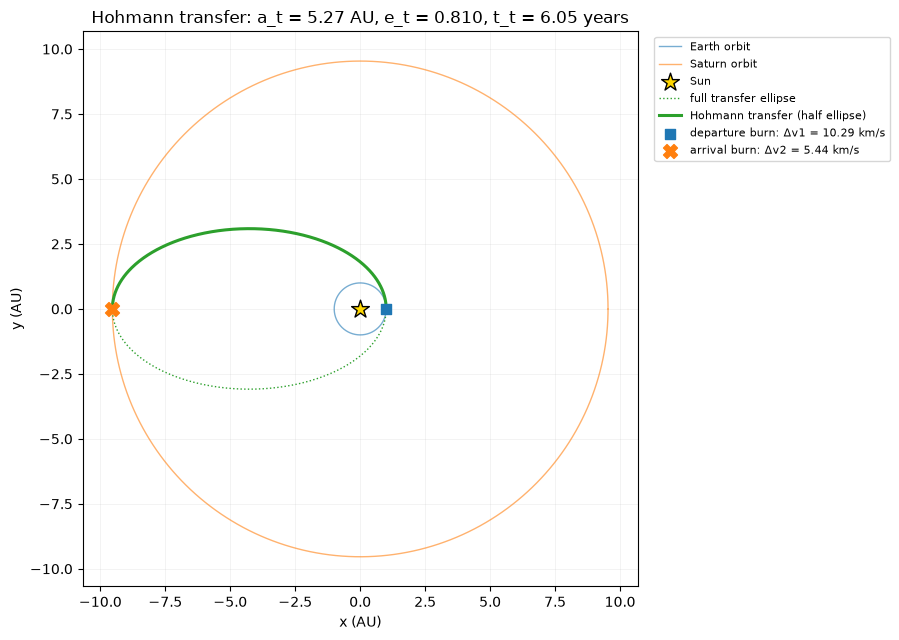

In [30]:
# Run only
plot_transfer_ellipse()

-*Your work for C1–C3. Type it here, or put a photo or scan of your handwritten work in your repository.*

> **[Report R1] What does the direct transfer look like, and what does it cost?**
> In your summary, give the flight time and the total $\Delta v$, and explain where these numbers come from: which formula, and which physical idea. Put your derivations of C1–C3 and the results table (Section G prints it for you) in your appendix.

### [Q&A] Section C — The Hohmann transfer

*These questions give you an idea of what you may be asked during the Q&A session. They are not a definitive question bank. Rather, thinking about these as you go through this notebook will help you deepen your understanding and prepare for the Q&A.*

- **Q-C1** ★ Describe the Hohmann transfer in non-technical terms, as if to someone who is not a scientist: what happens at departure, during the coast, and on arrival?
- **Q-C2** ★ What would happen to the spacecraft if it skipped the arrival burn $\Delta v_2$?
- **Q-C3** ★ Your function `hohmann_outer` works for any two circular orbits. How long would a Hohmann transfer to Jupiter (orbital radius 5.20 AU) take, and what would it cost? Why is reusable code like this valuable?
- **Q-C4** ★★ What does "tangent" mean here, and why are burns along the tangent an efficient choice?
- **Q-C5** ★★ What does $e_t\approx0.81$ tell you about the shape of the transfer ellipse? Sketch it, with the Sun at the correct point.
- **Q-C6** ★★ Why is $\Delta v_1$ larger than $\Delta v_2$?
- **Q-C7** ★★★ Could the spacecraft reach Saturn's orbit faster than on a Hohmann transfer? What would that cost, and why?

# Section D — Simulating the flight

All the work we've done up until now was *analytic*: we computed velocities and transfer times using exact formulas. 
We will now leverage Python and computing in a more essential way by performing a **simulation**, approximating the flight path of the spacecraft from Newton's law of gravitation alone. 

**The idea.** If we know the position and the velocity now, we can predict them a short time $\Delta t$ later. A derivative is a rate of change, so for a small $\Delta t$, we can approximate the next position and velocity by
$$
x(t+\Delta t)\approx x(t)+x'(t)\,\Delta t,\qquad v_x(t+\Delta t)\approx v_x(t)+v_x'(t)\,\Delta t,
$$
and the same for $y$ and $v_y$. Here $x'=v_x$ is the velocity and $v_x'=a_x$ is the acceleration. Repeating this small step thousands of times traces out the orbit. This is a **numerical simulation**: a `while` loop that repeats one small step until a stopping condition is met.

**The acceleration.** Gravity pulls toward the Sun with magnitude $\mu/r^2$, where $r=\sqrt{x^2+y^2}$. The unit vector pointing from the spacecraft toward the Sun is $-(x,y)/r$.

**[Do] D1.** Show that the components of the acceleration are
$$
a_x=-\frac{\mu x}{r^3},\qquad a_y=-\frac{\mu y}{r^3}.
$$

**When to stop.** We want to stop at aphelion, the point farthest from the Sun. On the way out the distance $r$ increases, and at aphelion it stops increasing. Differentiating $r^2=x^2+y^2$ with respect to $t$ gives
$$
r\,\frac{dr}{dt}=x\,v_x+y\,v_y,
$$
so the spacecraft is still moving outward as long as $x\,v_x+y\,v_y\ge 0$. This is the first-derivative test from calculus, applied to the function $r(t)$.

**[Do] D2.** Complete the six `TODO` lines in `simulate_transfer` below. The spacecraft starts at Earth's distance from the Sun, on the positive $x$-axis, moving in the $+y$ direction with speed `v_start`. Update the velocity first, and then update the position using the **new** velocity.

In [31]:
def simulate_transfer(v_start, dt):
    """Fly a spacecraft from Earth's orbit by stepping Newton's law forward in time.
    Stops at aphelion, when the distance from the Sun stops increasing (or after 30 years).
    Returns the flight time (s) and the final distance from the Sun (m)."""
    # Starting state: at Earth's distance, moving perpendicular to the Sun-spacecraft line
    x = r_earth
    y = 0.0
    vx = 0.0
    vy = v_start
    t = 0.0
    start_recording()            # for the plots: you can ignore this line
    record(t, x, y, vx, vy)      # for the plots: you can ignore this line

#Counts the number of iterations, used
    i = 0
    while x*vx + y*vy >= 0 and t < 30*year:
        i += 1
        r = np.sqrt(x**2 + y**2)
        ax = (-mu*x)/ (r**3)   # TODO: x-component of the acceleration (D1)
        ay = (-mu*y)/ (r**3)    # TODO: y-component of the acceleration (D1)
        vx = vx + (ax*dt)   # TODO: new vx, from the old vx, ax and dt
        vy = vy + (ay*dt)   # TODO: new vy, from the old vy, ay and dt
        x = x + (vx * dt)  # TODO: new x, from the old x, the NEW vx and dt
        y = y + (vy * dt)       # TODO: new y, from the old y, the NEW vy and dt
        t = t + dt
        record(t, x, y, vx, vy)  # for the plots: you can ignore this line

    print (i)

    r = np.sqrt(x**2 + y**2)
    return t, r

**[Do] D3.** Run the simulation with the Hohmann departure speed `v_start = v_p` from Section C and a time step of one day. Compare the flight time and the final distance with $t_t$ and $r_2$ from Section C. Then run the plot cell.

In [32]:
t_sim = None
r_sim = None

if v_p is None:
    print("Complete Section C first.")
else:
    dt = 1*day
    t_sim, r_sim = simulate_transfer(v_p, dt)
    print(f"Simulation (dt = {seconds_to_days(dt):g} day): turned around after {seconds_to_years(t_sim):.3f} years at {r_sim/AU:.3f} AU")
    print(f"Hohmann formulas (Section C):     t_t = {seconds_to_years(t_t):.3f} years, r_2 = {r_saturn/AU:.3f} AU")
    if t_sim >= 30*year:
        print("The spacecraft never turned around. Check the acceleration: it must point toward the Sun.")
    elif abs(r_sim/r_saturn - 1) < 0.01 and abs(t_sim/t_t - 1) < 0.01:
        print("Check: OK. The simulation agrees with the formulas to within 1%.")
    else:
        print("Check: the simulation and the formulas differ by more than 1%. Look at your six TODO lines again.")

2213
Simulation (dt = 1 day): turned around after 6.059 years at 9.545 AU
Hohmann formulas (Section C):     t_t = 6.046 years, r_2 = 9.537 AU
Check: OK. The simulation agrees with the formulas to within 1%.


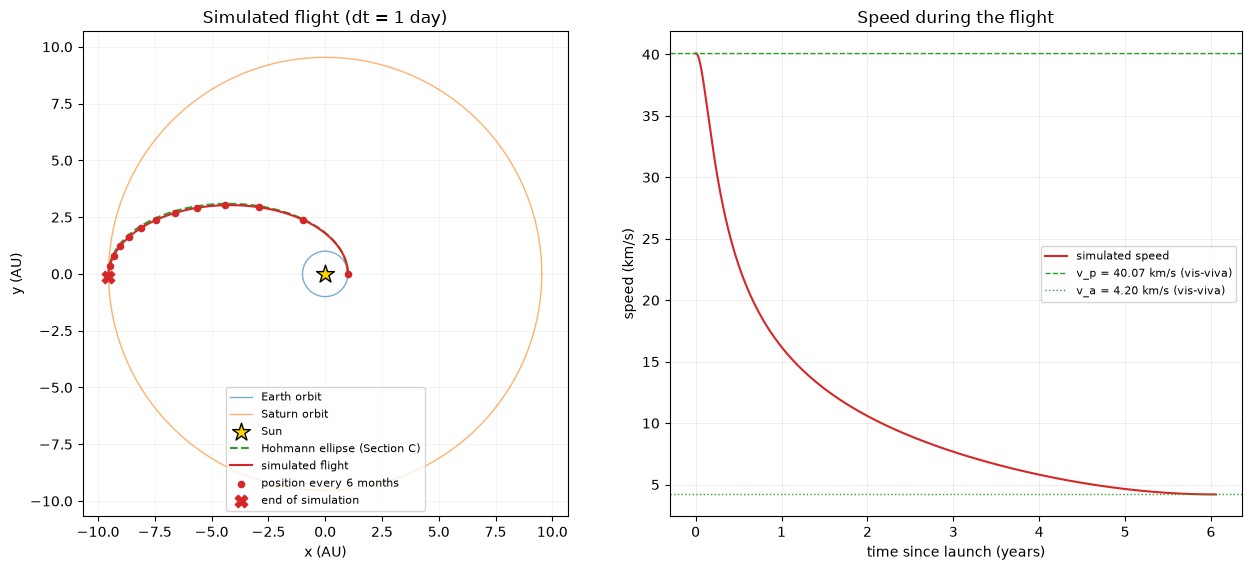

In [33]:
# Run only
plot_flight()

**[Do] D4 — Experiments.** In the next cell, change one thing at a time, run the cell, and write down what happens.

- Set `dt_test` to `10*day`, then to `0.1*day` (with `v_test = v_p`). How does the final distance change? Which time step would you trust, and why?
- Set `v_test` to `1.01*v_p`, then to `0.99*v_p` (with `dt_test = 1*day`). How far from Saturn's orbit does a 1% error in the departure speed put you?
- Set `v_test` to `43000` (that is, 43 km/s). What happens, and why?

22087
dt = 0.1 days, v_start = 40.07 km/s:
  turned around after 6.047 years at 9.537 AU (Saturn's orbit: 9.537 AU)


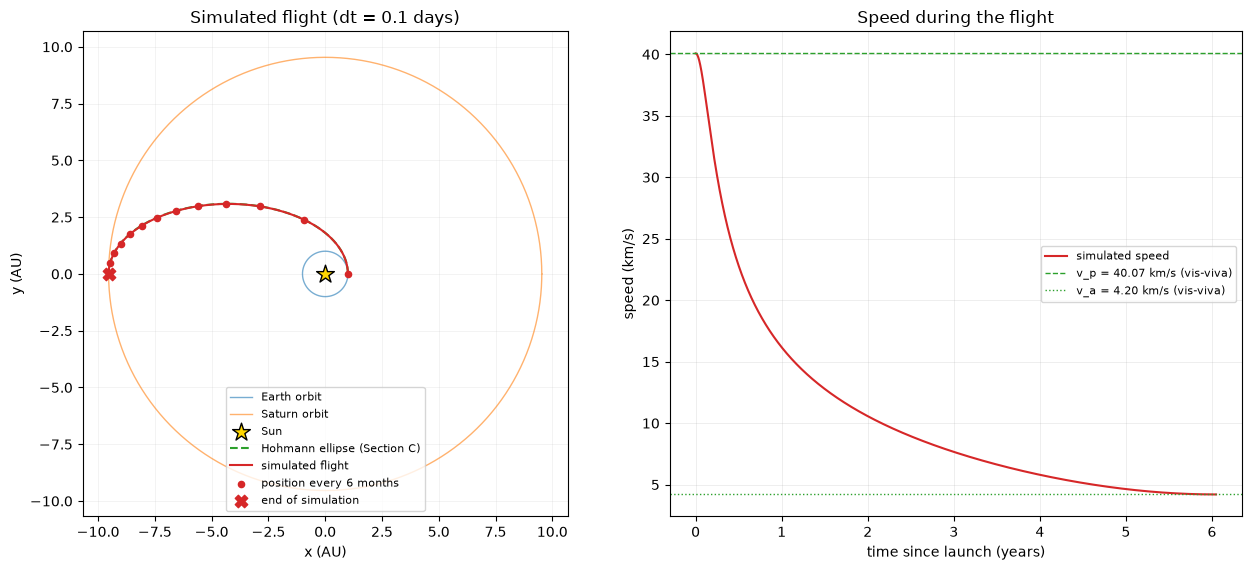

In [34]:
# D4: experiments. Change these two numbers, run the cell, and compare.
dt_test = 0.1 * 3600 * 24
v_test = v_p

if v_test is None:
    print("Complete Section C first.")
else:
    t_test, r_test = simulate_transfer(v_test, dt_test)
    print(f"dt = {seconds_to_days(dt_test):g} days, v_start = {mps_to_kms(v_test):.2f} km/s:")
    if t_test >= 30*year:
        print(f"  no turning point within 30 years; distance after 30 years: {r_test/AU:.1f} AU")
    else:
        print(f"  turned around after {seconds_to_years(t_test):.3f} years at {r_test/AU:.3f} AU (Saturn's orbit: {r_saturn/AU:.3f} AU)")
    plot_flight()

> **[Report R2] What did the computer let you do that formulas alone could not?**
> What can the simulation confirm, and how did you check that it can be trusted (think about the time step)? You might also think about what a simulation could handle that the Hohmann formulas cannot (for example, the gravity of other planets).

### [Q&A] Section D — Simulating the flight

*These questions give you an idea of what you may be asked during the Q&A session. They are not a definitive question bank. Rather, thinking about these as you go through this notebook will help you deepen your understanding and prepare for the Q&A.*

- **Q-D1** ★ In your own words, what does one pass through the `while` loop do? Why does the loop stop at aphelion?
- **Q-D2** ★ What is `dt`? What happens to the accuracy, and to the computing time, when you make it smaller?
- **Q-D3** ★★ The update $x_{\text{new}}=x+v_x\,\Delta t$ is a tangent-line (linear) approximation. Explain this with the geometric meaning of the derivative. Why does it get better as $\Delta t\to0$?
- **Q-D4** ★★ Explain the stopping condition $x\,v_x+y\,v_y\ge0$. Where does it come from, and how is it related to finding a maximum with the first derivative?
- **Q-D5** ★★ The speed drops from about 40 km/s to about 4 km/s during the flight. Explain this with conservation of energy, and with Kepler's second law. (Look at the 6-month markers in the plot.)
- **Q-D6** ★★ How far off is the aphelion after a 1% error in the departure speed? What does this mean for a real mission?
- **Q-D7** ★★★ How would you add the gravity of Jupiter to the simulation? Why is this a small change in code, but practically impossible with formulas alone?

# Section E — The launch window

A transfer orbit is useless if Saturn is somewhere else when the spacecraft arrives. The spacecraft's path and Saturn's path **intersect** at the aphelion of the transfer ellipse, but that is not enough: we need a **collision** (a rendezvous), with the spacecraft and Saturn at that point **at the same time**.

**[Do] E1 — The launch angle.** Find the phase angle $\phi^*=\theta_{\text{Saturn}}-\theta_{\text{Earth}}$ that is needed at the moment of launch. Draw a sketch with the Sun, Earth at launch, Saturn at launch, and the arrival point. Hints:
- The spacecraft flies half an ellipse. Where is the arrival point, measured from Earth's position at launch?
- During the flight time $t_t$, Saturn moves through the angle $n_2t_t$. Where must Saturn be at launch so that it reaches the arrival point at the right moment?

<details>
<summary><b>Check your answer to E1</b> (open this only after you have tried)</summary>

$$
\phi^*=\pi-n_2t_t \pmod{2\pi}.
$$

</details>

In [35]:
phi_req = (np.pi - (n_saturn * t_t)) % (2*np.pi)   # TODO: the required phase angle phi* from E1. Use n_saturn and t_t, and wrap the angle with % (2*np.pi)

if phi_req is None:
    print("Complete phi_req, then run this cell again.")
else:
    print(f"Required phase angle at launch phi* = {phi_req:.4f} rad = {np.degrees(phi_req):.2f} degrees")
    print(f"Phase angle today          phi_now = {phi_now:.4f} rad = {np.degrees(phi_now):.2f} degrees")
    if abs(np.degrees(phi_req) - 106.09) < 0.1:
        print("Check: OK")
    else:
        print("Check: expected about 106.09 degrees. Look at your formula again.")

Required phase angle at launch phi* = 1.8517 rad = 106.09 degrees
Phase angle today          phi_now = 1.8137 rad = 103.92 degrees
Check: OK


**[Do] E2.** The phase angle decreases at the constant rate $n_1-n_2$. The angle by which it still has to decrease is
$$
\Delta\phi=(\phi_{\text{now}}-\phi^*)\bmod 2\pi,
\qquad\text{so}\qquad
t_{\text{wait}}=\frac{\Delta\phi}{n_1-n_2}.
$$
Compute $t_{\text{wait}}$ with this formula. Then run the plot cell: it shows the positions today, at launch, and at arrival.

In [36]:
t_wait = ((phi_now - phi_req)%(2*np.pi))/(n_earth - n_saturn)  # TODO: the waiting time from the formula in E2. Use phi_now, phi_req, n_earth, n_saturn and % (2*np.pi)

if t_wait is None:
    print("Complete t_wait, then run this cell again.")
else:
    print(f"Launch window by formula: wait {seconds_to_days(t_wait):.1f} days = {seconds_to_years(t_wait):.3f} years")
    t_syn = 2*np.pi/(n_earth - n_saturn)
    print(f"Launch windows repeat every {seconds_to_days(t_syn):.0f} days (the synodic period)")
    if 0 <= t_wait < t_syn:
        print("Check: OK")
    else:
        print("Check: the waiting time must be between 0 and one synodic period. Did you wrap the angle with % (2*np.pi)?")


Launch window by formula: wait 375.8 days = 1.029 years
Launch windows repeat every 378 days (the synodic period)
Check: OK


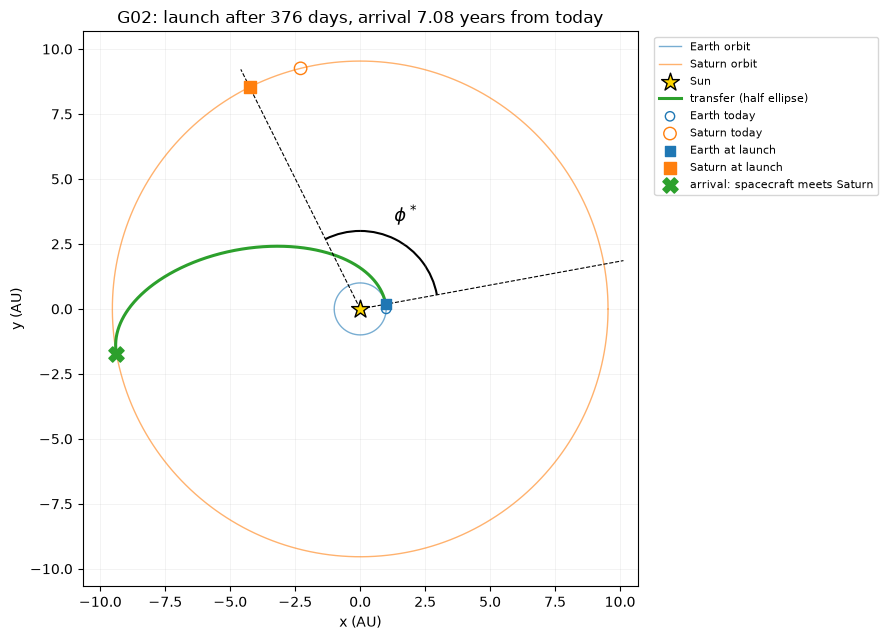

In [37]:
# Run only
plot_launch_geometry(t_wait)

> **[Report R3] When can your mission launch, and how did you determine the launch angle?**
> Give $\phi_{\text{now}}$, $\phi^*$, the waiting time and the arrival time (in years from today). Explain the reasoning behind $\phi^*$ (a sketch in your appendix helps).

### [Q&A] Section E — The launch window

*These questions give you an idea of what you may be asked during the Q&A session. They are not a definitive question bank. Rather, thinking about these as you go through this notebook will help you deepen your understanding and prepare for the Q&A.*

- **Q-E1** ★ Why can't the spacecraft simply launch today and aim at Saturn?
- **Q-E2** ★ Explain the formula $\phi^*=\pi-n_2t_t$ with a sketch.
- **Q-E3** ★ Every group has the same $\phi^*$, but different groups have different waiting times. Why?
- **Q-E4** ★★ The paths of the spacecraft and of Saturn intersect at the aphelion. Why is that not enough? Explain the difference between two parametric curves *intersecting* and two moving objects *colliding*.
- **Q-E5** ★★ Why does the phase angle decrease over time, and why at the rate $n_1-n_2$?
- **Q-E6** ★★ What is the synodic period, and why is your waiting time always shorter than it? Launch windows to Saturn come about once a year, but launch windows to Mars come only about every 26 months. Why the difference?
- **Q-E7** ★★★ A crewed mission also has to come back. Which phase angle does the return trip from Saturn to Earth need? Roughly how long would the crew have to wait at Saturn?
- **Q-E8** ★★★ Saturn's real orbit is slightly elliptical and tilted by about $2.5^\circ$ relative to Earth's. How would these facts affect the launch window?

## Run-only extra — watch the whole mission

The next cell animates the whole mission: the wait for the launch window, the launch, and the coast to Saturn's orbit. It takes up to a minute to build. You do not need to change anything. The animation adds a few MB to the notebook file; you may clear this cell's output before you upload the notebook to GitHub.

The animation moves the spacecraft as Kepler's laws require:

1. **First law:** the transfer path is an ellipse with the Sun at one focus.
2. **Second law:** the line from the Sun to the spacecraft sweeps out equal areas in equal times, so the spacecraft is fast near perihelion and slow near aphelion.
3. **Third law:** the flight time is half the period of the transfer ellipse, $t_t=\pi\sqrt{a_t^3/\mu}$.

To get the second law right, the helper code solves *Kepler's equation* $M=E-e\sin E$ at every frame. You do not need to know how this works. Your simulation in Section D shows the same slowing down without Kepler's equation, because it follows Newton's law directly.

"Exact" here means exact *within our simplified model* (circular planetary orbits in one plane, and only the Sun's gravity). It is not exact for a real mission.

In [38]:
# Run only (takes up to a minute)
animate_delayed_launch(t_wait, motion_model="exact")

The animation can also move the spacecraft along the same ellipse at a constant angular rate (`motion_model="simple"`). That looks plausible, but its timing is wrong. The next cell compares the two timing models by marking the spacecraft's position after equal time steps, and plots the exact speed along the transfer, which you can compare with the right-hand plot in Section D.

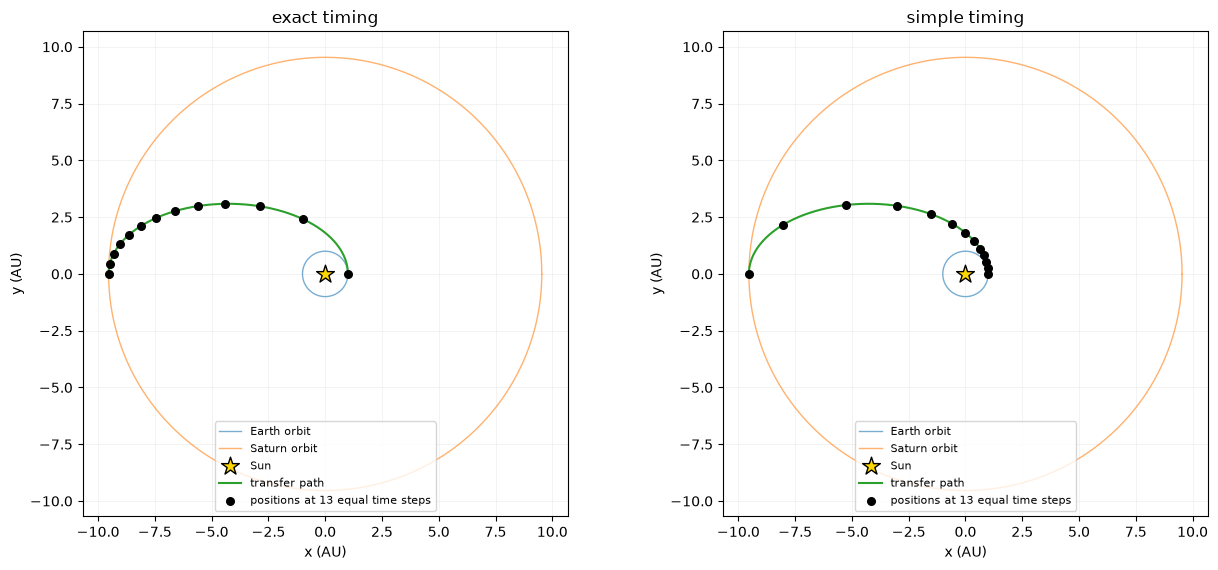

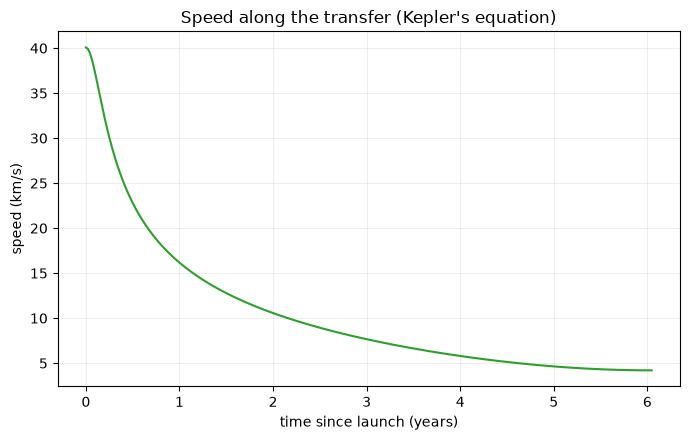

In [39]:
# Run only
plot_equal_time_markers()
plot_transfer_speed_profile()

In [40]:
# Optional: save an animation as a GIF (this takes a while and needs the pillow package).
# Remove the # at the start of the next two lines to run them.
# anim = animate_delayed_launch(t_wait, motion_model="exact")
# anim.save(f"{GROUP_CODE}_mission_animation.gif", writer="pillow", fps=20)

# Section F — Is the mission feasible?

Now put everything together and compare it with your group's mission parameters (printed in the Setup section):

- **Time.** The drone must reach Saturn's orbit within `deadline_years` from today. The total time is the waiting time plus the flight time.
- **$\Delta v$.** The mission needs $\Delta v_1+\Delta v_2$, plus the fixed allowance `arrival_allowance_kms` for the final approach to Titan. This total must not exceed `dv_budget_kms`.

**[Do] F1.** Complete the cell below. Use `if`/`else` to print PASS or FAIL for each constraint, together with the margin: how much time or $\Delta v$ is left over, or how much is missing.

A FAIL is not a coding error. It is a result, and often the most interesting one.

In [41]:
total_years = (t_wait + t_t)/(3600*24*365)     # TODO: waiting time + flight time, in years
mission_dv_kms = ((dv1 + dv2)/10**3) + arrival_allowance_kms    # TODO: dv1 + dv2 + the arrival allowance, in km/s

if total_years is None or mission_dv_kms is None:
    print("Complete total_years and mission_dv_kms, then run this cell again.")
elif not (6 < total_years < 7.2) or not (15 < mission_dv_kms < 17):
    print(f"Check: total_years = {total_years:.4g} and mission_dv_kms = {mission_dv_kms:.4g} look wrong.")
    print("Expected: a total time of 6 to 7 years and a mission delta-v of about 16 km/s.")
    print("Did you convert seconds to years and m/s to km/s (seconds_to_years, mps_to_kms)?")
else:
    print(f"Group {GROUP_CODE}")
    print(f"Arrival after {total_years:.2f} years (deadline: {deadline_years:.2f} years)")
    # TODO: use if/else to print "Time constraint: PASS" or "Time constraint: FAIL",
    #       and print the margin deadline_years - total_years (in years and in days)

    print(f"Mission delta-v {mission_dv_kms:.2f} km/s (budget: {dv_budget_kms:.2f} km/s)")
    # TODO: use if/else to print "Delta-v constraint: PASS" or "Delta-v constraint: FAIL",
    #       and print the margin dv_budget_kms - mission_dv_kms

Group G02
Arrival after 7.08 years (deadline: 6.50 years)
Mission delta-v 16.03 km/s (budget: 15.50 km/s)


**[Do] F2.** Go back to the simplifying assumptions in the introduction. Which of them could change your verdict? For each constraint, would a more realistic model make it easier or harder to meet?

> **[Report R4] Can your mission reach Titan within its constraints, and how far can you trust that conclusion?**
> State the verdict for both constraints, with the margins. Name the assumption that matters most for *your* verdict, and suggest one plan for what to do next or instead (for example: use a gravity assist, choose a faster transfer, wait for a different launch window, or build a lighter spacecraft).

### [Q&A] Section F — Feasibility and limitations

*These questions give you an idea of what you may be asked during the Q&A session. They are not a definitive question bank. Rather, thinking about these as you go through this notebook will help you deepen your understanding and prepare for the Q&A.*

- **Q-F1** ★★ How large are your margins? Are they larger than the errors you would expect from the model's assumptions (for example, Saturn's orbit is not exactly circular)?
- **Q-F2** ★★ The Cassini spacecraft, launched to Saturn in 1997, used gravity assists at Venus (twice), Earth and Jupiter. How might a gravity assist change the $\Delta v$ and the flight time? Why does our model leave it out?
- **Q-F3** ★★ Independent of trajectory, there is (generally) a trade-off between flight time and $\Delta v$. Discuss this and how this trade-off would affect a real-world mission.

# Section G — Writing your one-page summary

The math part of your report is **one page**, plus **up to two pages of appendix**. The page is not a list of answers to this notebook. It is a short scientific argument that answers one question:

> *Can our drone reach Titan on a direct Hohmann transfer within our mission constraints, and what does this simple model tell the mission team?*

Your four report items R1–R4 are the building blocks. A good page connects them so that each result leads to the next and the conclusion follows from the numbers.

## The appendix (up to two pages)

- **Table A1 — key results.** The next cell prints it for you.
- **One or two figures.** For example, the launch geometry (Section E) or your simulated flight (Section D). The second cell below saves them as PNG files. Every figure needs a number and a caption that tells the reader what to look at, and the main text must refer to it.
- **The derivations that carry your argument.** For example, $a_t$ and $e_t$ (C1), $t_t$ (C2) and $\phi^*$ (E1). Typeset them, and keep them short. Only include derivations that are relevant to *your* conclusions.

In [42]:
# Run only: your key results, as Table A1 for your appendix
print_results_table()

| Quantity | Symbol | Value |
|---|---|---|
| Group code |  | G02 |
| Earth's orbital speed | $v_{\text{circ}}(r_1)$ | 29.79 km/s |
| Saturn's orbital speed | $v_{\text{circ}}(r_2)$ | 9.64 km/s |
| Semi-major axis of the transfer ellipse | $a_t$ | 5.269 AU |
| Eccentricity of the transfer ellipse | $e_t$ | 0.810 |
| Flight time (Hohmann formula) | $t_t$ | 6.046 years |
| Speed on the ellipse at departure | $v_p$ | 40.07 km/s |
| Speed on the ellipse at arrival | $v_a$ | 4.20 km/s |
| Departure burn | $\Delta v_1$ | 10.29 km/s |
| Arrival burn | $\Delta v_2$ | 5.44 km/s |
| Flight time (simulation, dt = 1 day) |  | 6.059 years |
| Aphelion distance (simulation, dt = 1 day) |  | 9.545 AU |
| Phase angle today | $\phi_{\text{now}}$ | 1.8137 rad = 103.92° |
| Required phase angle at launch | $\phi^*$ | 1.8517 rad = 106.09° |
| Waiting time until launch | $t_{\text{wait}}$ | 376 days |
| Arrival, years from today |  | 7.08 years |
| Arrival deadline |  | 6.50 years |
| Mission $\Delta v$ (incl. Titan-approach allowance) |  | 16.03 km/s |
| $\Delta v$ budget |  | 15.50 km/s |

In [43]:
# Run only: save the main figures as PNG files (for your appendix and your GitHub repository)
export_report_figures()

Saved G02_phase_angle_today.png
Saved G02_hohmann_transfer.png
2213
Saved G02_simulated_flight.png
Saved G02_launch_geometry.png


# Section H — Sample Math questions

## Questions from Sections A–F

### Section A — Circular orbits

- **Q-A1** ★ The circular orbit model is described using a parametric curve. Which parameter does it depend on and what is its physical meaning? What do $r$ and $n$ mean physically? What are the units of $n$?
- **Q-A2** ★★ Why are Saturn years longer than Earth years? Support your answer with a formula.
- **Q-A3** ★★★ Real planetary orbits are slightly elliptical (Earth: $e\approx0.017$; Saturn: $e\approx0.052$). Roughly how much does Saturn's distance from the Sun vary, and how could this affect the mission?

### Section B — Orbital energy and vis-viva

- **Q-B1** ★ What does the sign of $\varepsilon$ tell you? Which planet is more tightly bound to the Sun, Earth or Saturn? What does 'more tightly bound' mean here?
- **Q-B2** ★ On an elliptical orbit, where is the spacecraft fastest, and where is it slowest? How does this relate to conservation of energy?
- **Q-B3** ★★ By setting $\varepsilon=0$, you can find the speed a spacecraft needs to escape the Sun's gravity, starting at a radius $r$ from the Sun. Explain why this works. Do this computation for a spacecraft starting from Earth's orbit, by setting $r = r_1$.
- **Q-B4** ★★ The vis-viva equation contains $a$ but not $e$. What does this mean physically?
- **Q-B5** ★★★ The energy difference between Saturn's orbit and Earth's orbit is about $4\times10^{8}$ J per kilogram. Why can't we simply convert this energy difference to obtain our mission's $\Delta v$?

### Section C — The Hohmann transfer

- **Q-C1** ★ Describe the Hohmann transfer in non-technical terms, as if to someone who is not a scientist: what happens at departure, during the coast, and on arrival?
- **Q-C2** ★ What would happen to the spacecraft if it skipped the arrival burn $\Delta v_2$?
- **Q-C3** ★ Your function `hohmann_outer` works for any two circular orbits. How long would a Hohmann transfer to Jupiter (orbital radius 5.20 AU) take, and what would it cost? Why is reusable code like this valuable?
- **Q-C4** ★★ What does "tangent" mean here, and why are burns along the tangent an efficient choice?
- **Q-C5** ★★ What does $e_t\approx0.81$ tell you about the shape of the transfer ellipse? Sketch it, with the Sun at the correct point.
- **Q-C6** ★★ Why is $\Delta v_1$ larger than $\Delta v_2$?
- **Q-C7** ★★★ Could the spacecraft reach Saturn's orbit faster than on a Hohmann transfer? What would that cost, and why?

### Section D — Simulating the flight

- **Q-D1** ★ In your own words, what does one pass through the `while` loop do? Why does the loop stop at aphelion?
- **Q-D2** ★ What is `dt`? What happens to the accuracy, and to the computing time, when you make it smaller?
- **Q-D3** ★★ The update $x_{\text{new}}=x+v_x\,\Delta t$ is a tangent-line (linear) approximation. Explain this with the geometric meaning of the derivative. Why does it get better as $\Delta t\to0$?
- **Q-D4** ★★ Explain the stopping condition $x\,v_x+y\,v_y\ge0$. Where does it come from, and how is it related to finding a maximum with the first derivative?
- **Q-D5** ★★ The speed drops from about 40 km/s to about 4 km/s during the flight. Explain this with conservation of energy, and with Kepler's second law. (Look at the 6-month markers in the plot.)
- **Q-D6** ★★ How far off is the aphelion after a 1% error in the departure speed? What does this mean for a real mission?
- **Q-D7** ★★★ How would you add the gravity of Jupiter to the simulation? Why is this a small change in code, but practically impossible with formulas alone?

### Section E — The launch window

- **Q-E1** ★ Why can't the spacecraft simply launch today and aim at Saturn?
- **Q-E2** ★ Explain the formula $\phi^*=\pi-n_2t_t$ with a sketch.
- **Q-E3** ★ Every group has the same $\phi^*$, but different groups have different waiting times. Why?
- **Q-E4** ★★ The paths of the spacecraft and of Saturn intersect at the aphelion. Why is that not enough? Explain the difference between two parametric curves *intersecting* and two moving objects *colliding*.
- **Q-E5** ★★ Why does the phase angle decrease over time, and why at the rate $n_1-n_2$?
- **Q-E6** ★★ What is the synodic period, and why is your waiting time always shorter than it? Launch windows to Saturn come about once a year, but launch windows to Mars come only about every 26 months. Why the difference?
- **Q-E7** ★★★ A crewed mission also has to come back. Which phase angle does the return trip from Saturn to Earth need? Roughly how long would the crew have to wait at Saturn?
- **Q-E8** ★★★ Saturn's real orbit is slightly elliptical and tilted by about $2.5^\circ$ relative to Earth's. How would these facts affect the launch window?

### Section F — Feasibility and limitations

- **Q-F1** ★★ How large are your margins? Are they larger than the errors you would expect from the model's assumptions (for example, Saturn's orbit is not exactly circular)?
- **Q-F2** ★★ The Cassini spacecraft, launched to Saturn in 1997, used gravity assists at Venus (twice), Earth and Jupiter. How might a gravity assist change the $\Delta v$ and the flight time? Why does our model leave it out?
- **Q-F3** ★★ Independent of trajectory, there is (generally) a trade-off between flight time and $\Delta v$. Discuss this and how this trade-off would affect a real-world mission.

## Big-picture questions

- **Q-M1** ★ What is a mathematical model? What are the inputs, the outputs and the assumptions of your Hohmann model?
- **Q-M2** ★ Where did derivatives appear in this project? Give at least three places.
- **Q-M3** ★ What are parametric equations and polar coordinates, and where did you use them? How do you convert between polar and Cartesian coordinates?
- **Q-M4** ★★ Name one thing the model gets right, and one thing it gets wrong, about a real mission to Titan.
- **Q-M5** ★★ Why is it valuable to combine mathematical models with computer code? What can code do that algebra and a calculator cannot? Give an example from your own work.
- **Q-M6** ★★ How did you check that your code was correct?
- **Q-M7** ★★ How does the trajectory constrain the rest of your mission: power, communication, instruments, Titan's season on arrival, the crew?
- **Q-M8** ★★★ If you had one more week, what would you add to the model first, and why?
- **Q-M9** ★ Pick one figure, table or derivation in your appendix. Why did you include it, and what should the reader see in it?